# 北京多站点空气质量分析与次日 PM2.5 预测

贾子硕 · 2026104376 · 2026秋《基于Python的问题解析》期末大作业

本Notebook展示数据处理、模型比较和误差分析结果。默认读取随附结果；将 `RETRAIN` 设为 `True` 可重新运行实验。

**核心问题：**在第t日结束时，能否仅依靠已观测历史，比“明天等于今天”更准确地预测第t+1日PM2.5？

In [1]:
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
assert (ROOT / "run_analysis.py").exists(), "请将工作目录设为本项目根目录"
RETRAIN = False
if RETRAIN or not (ROOT / "results/metrics.csv").exists():
    subprocess.run([sys.executable, "run_analysis.py"], cwd=ROOT, check=True)
OUT = ROOT / "results"
def read_json(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))
def show_fig(name):
    display(Image(filename=str(OUT / "figures" / name), width=950))
print("Python:", sys.version.split()[0])
print("模式:", "重新运行实验" if RETRAIN else "读取已保存的结果")

Python: 3.10.21
模式: 读取已保存的结果


## 1. 来源、原始数据与质量审计

[UCI官方数据页面](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality)，DOI: [10.24432/C5RK5G](https://doi.org/10.24432/C5RK5G)，许可CC BY 4.0。原始归档不修改，只读取内层PRSA2017归档中的12个站点CSV。全样本质量审计用于发现结构问题；后续探索性图表仅使用开发期。

In [2]:
audit = read_json("data_audit.json")
display(pd.Series({k: audit[k] for k in ["raw_rows","raw_columns","station_count","start","end","duplicates","missing_hour_keys","daily_rows","invalid_pm_days","model_rows","development_rows","test_rows"]}, name="值").to_frame())
display(pd.DataFrame({"缺失条数":audit["missing_counts"],"缺失比例%":audit["missing_pct"]}))
print("SHA256:", audit["sha256"])

,值
raw_rows,420768
raw_columns,18
station_count,12
start,2013-03-01 00:00:00
end,2017-02-28 23:00:00
duplicates,0
missing_hour_keys,0
daily_rows,17532
invalid_pm_days,368
model_rows,16962


,缺失条数,缺失比例%
PM2.5,8739,2.0769
PM10,6449,1.5327
SO2,9021,2.1439
NO2,12116,2.8795
CO,20701,4.9198
O3,13277,3.1554
TEMP,398,0.0946
PRES,393,0.0934
DEWP,403,0.0958
RAIN,390,0.0927


SHA256: b04da438b2f331ac0ffd45aebdfec0d20d2367feb5f6948c4b1f7ce1191e33c4


## 2. 类与异常处理的实际调用

`AirQualityDataset` 封装读取、质量规则和聚合；`DataValidationError` 表达数据契约错误。下面刻意访问不存在的归档，捕获预期异常并打印提示，演示异常处理。输入文件缺失或损坏时，分析入口会停止并报告原因。

In [3]:
from src.data import AirQualityDataset, DataValidationError, build_features, calendar_folds, TEST_START
try:
    AirQualityDataset(ROOT / "data/raw/example_missing.zip").load()
except FileNotFoundError as exc:
    print("预期异常已捕获:", exc)
finally:
    print("示例结束；实际分析仍使用已验证的官方归档。")

预期异常已捕获: Data archive not found: D:\home_work\python\beijing_air_quality_final\data\raw\example_missing.zip
示例结束；实际分析仍使用已验证的官方归档。


## 3. 按日聚合与缺失处理

日均要求至少18小时；目标不插补；当日PM2.5缺失也排除以公平比较持续性。其他特征仅在训练折内插补。风向取sin/cos日均。保留高污染值，不用统计离群规则自动删去事件。

,station,date,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wind_sin,wind_cos,pm_hours,pm_max,pm_std,pm_evening
0,Aotizhongxin,2013-03-01,7.125000,10.750000,11.708333,22.583333,429.166667,63.875000,1.391667,1026.875000,-18.745833,0.0,3.254167,-0.020739,0.851335,24,24.0,5.041674,13.500000
1,Aotizhongxin,2013-03-02,30.750000,42.083333,36.625000,66.666667,824.916667,29.750000,0.616667,1026.850000,-15.937500,0.0,1.479167,0.050771,0.342961,24,93.0,27.423015,71.666667
2,Aotizhongxin,2013-03-03,76.916667,120.541667,61.291667,81.000000,1620.625000,19.125000,5.566667,1014.608333,-12.316667,0.0,1.658333,-0.037617,0.651403,24,117.0,31.264533,53.333333
3,Aotizhongxin,2013-03-04,22.708333,44.583333,22.869565,46.956522,617.391304,53.750000,9.962500,1017.650000,-11.683333,0.0,2.404167,-0.093243,0.024891,24,58.0,15.834687,39.833333
4,Aotizhongxin,2013-03-05,148.875000,183.791667,93.875000,132.833333,2357.958333,68.458333,6.291667,1010.900000,-7.525000,0.0,1.129167,0.340405,0.581588,24,226.0,47.053450,213.000000


特征组: {'history_calendar': 16, 'with_weather': 24, 'full': 30}


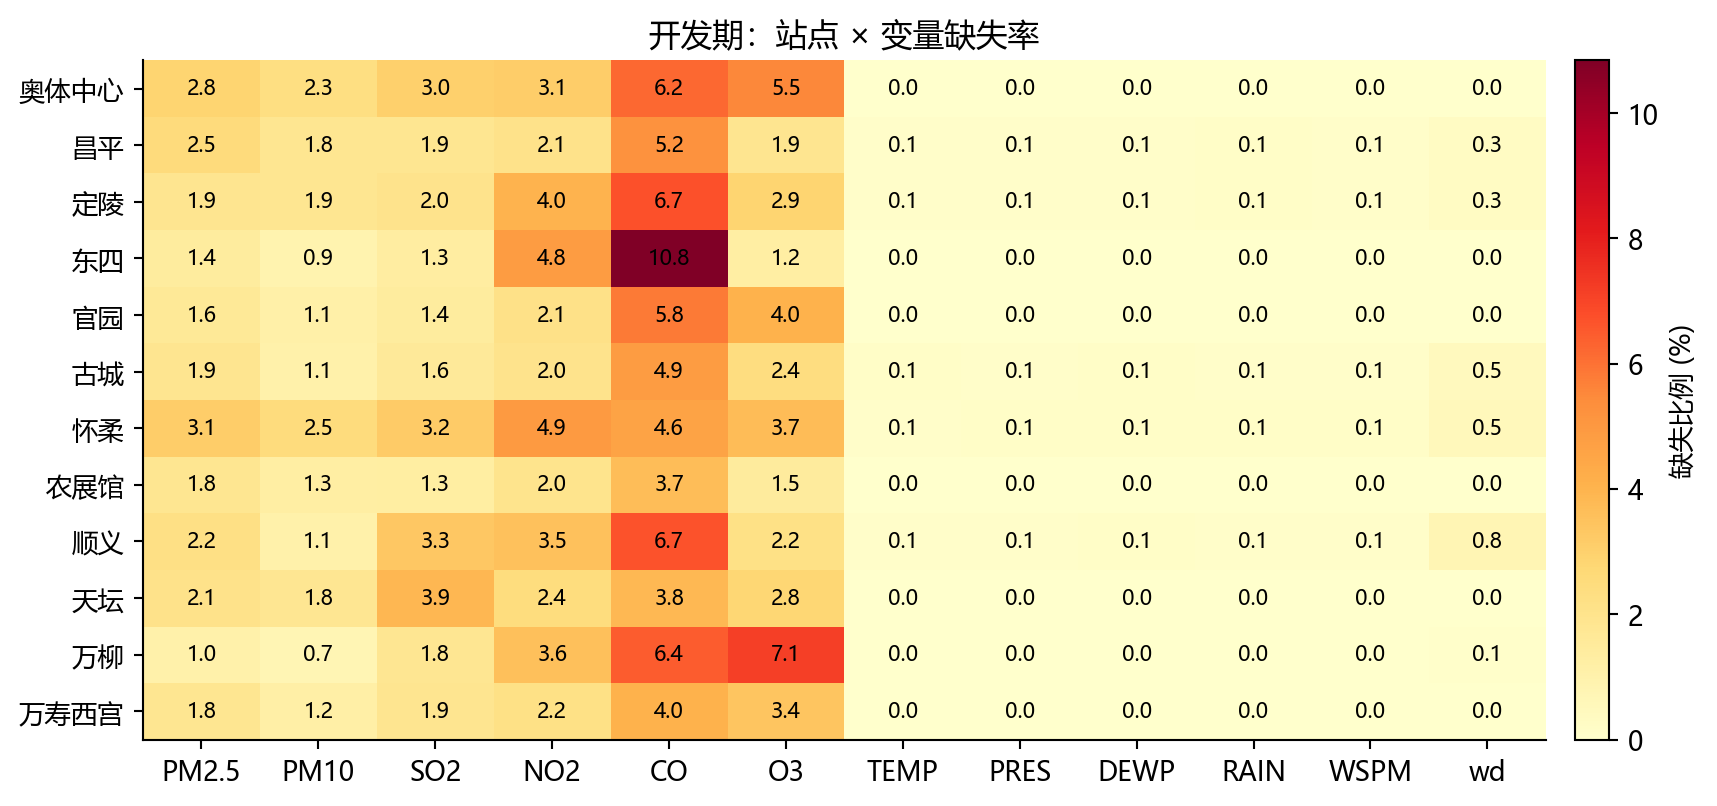

In [4]:
daily = pd.read_csv(ROOT / "data/processed/daily.csv", parse_dates=["date"])
frame, groups = build_features(daily)
display(daily.head())
print("特征组:", {k:len(v) for k,v in groups.items()})
show_fig("01_missing.png")

## 4. 分布、季节性与站点差异

均值和中位数不同反映上尾；不同统计层级权重不同。图中对数变换只用于观察，不改变主模型目标。站点等权平均描述这12个监测点的浓度，未按人口分布加权。

,结果
dev_hourly_pm_mean,80.407490
dev_hourly_pm_median,56.000000
dev_hourly_pm_p95,242.000000
dev_hourly_pm_max,999.000000
dev_daily_pm_mean,80.094807
dev_pm_missing_pct,2.019914
pm_pm10_spearman,0.904731
pm_wind_spearman,-0.435591
pm_persistence_spearman,0.523647
dev_target_p90,166.666667


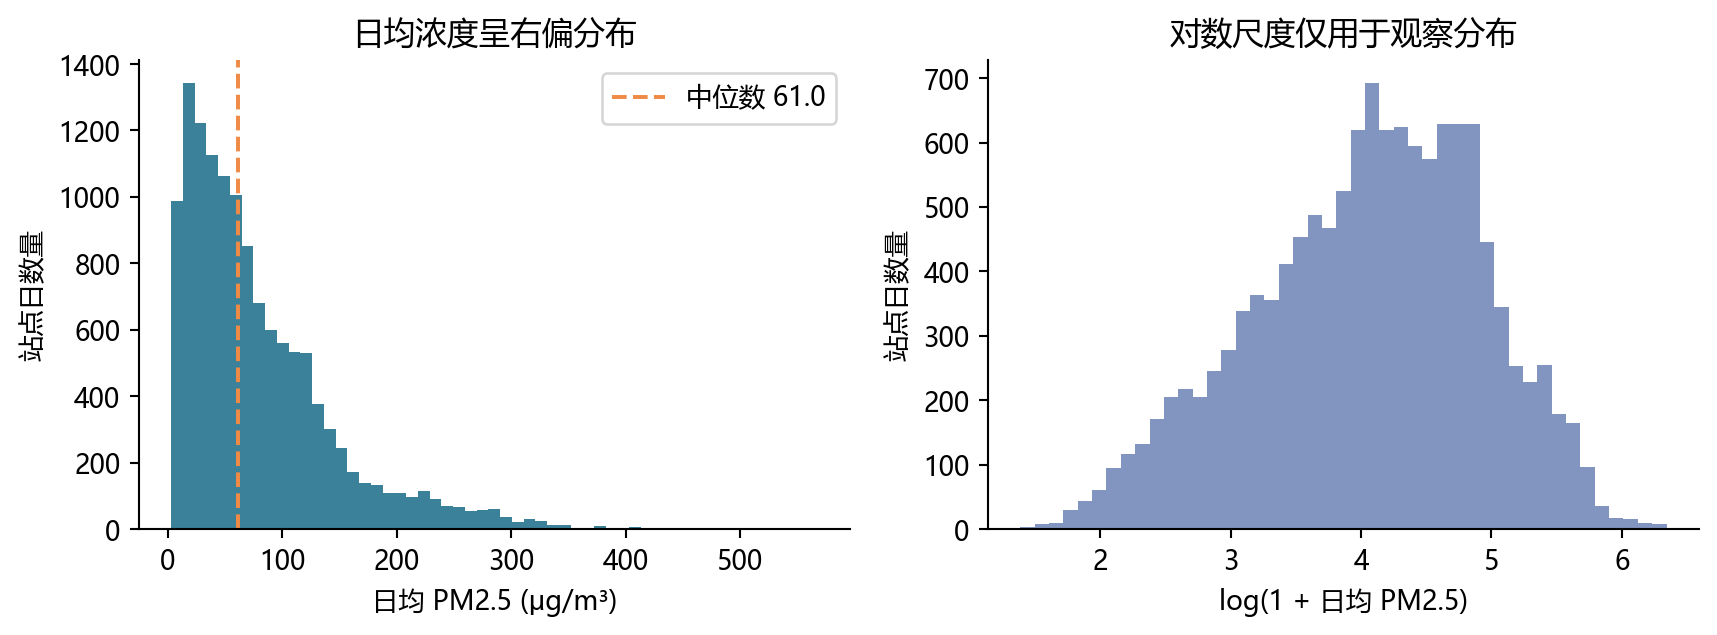

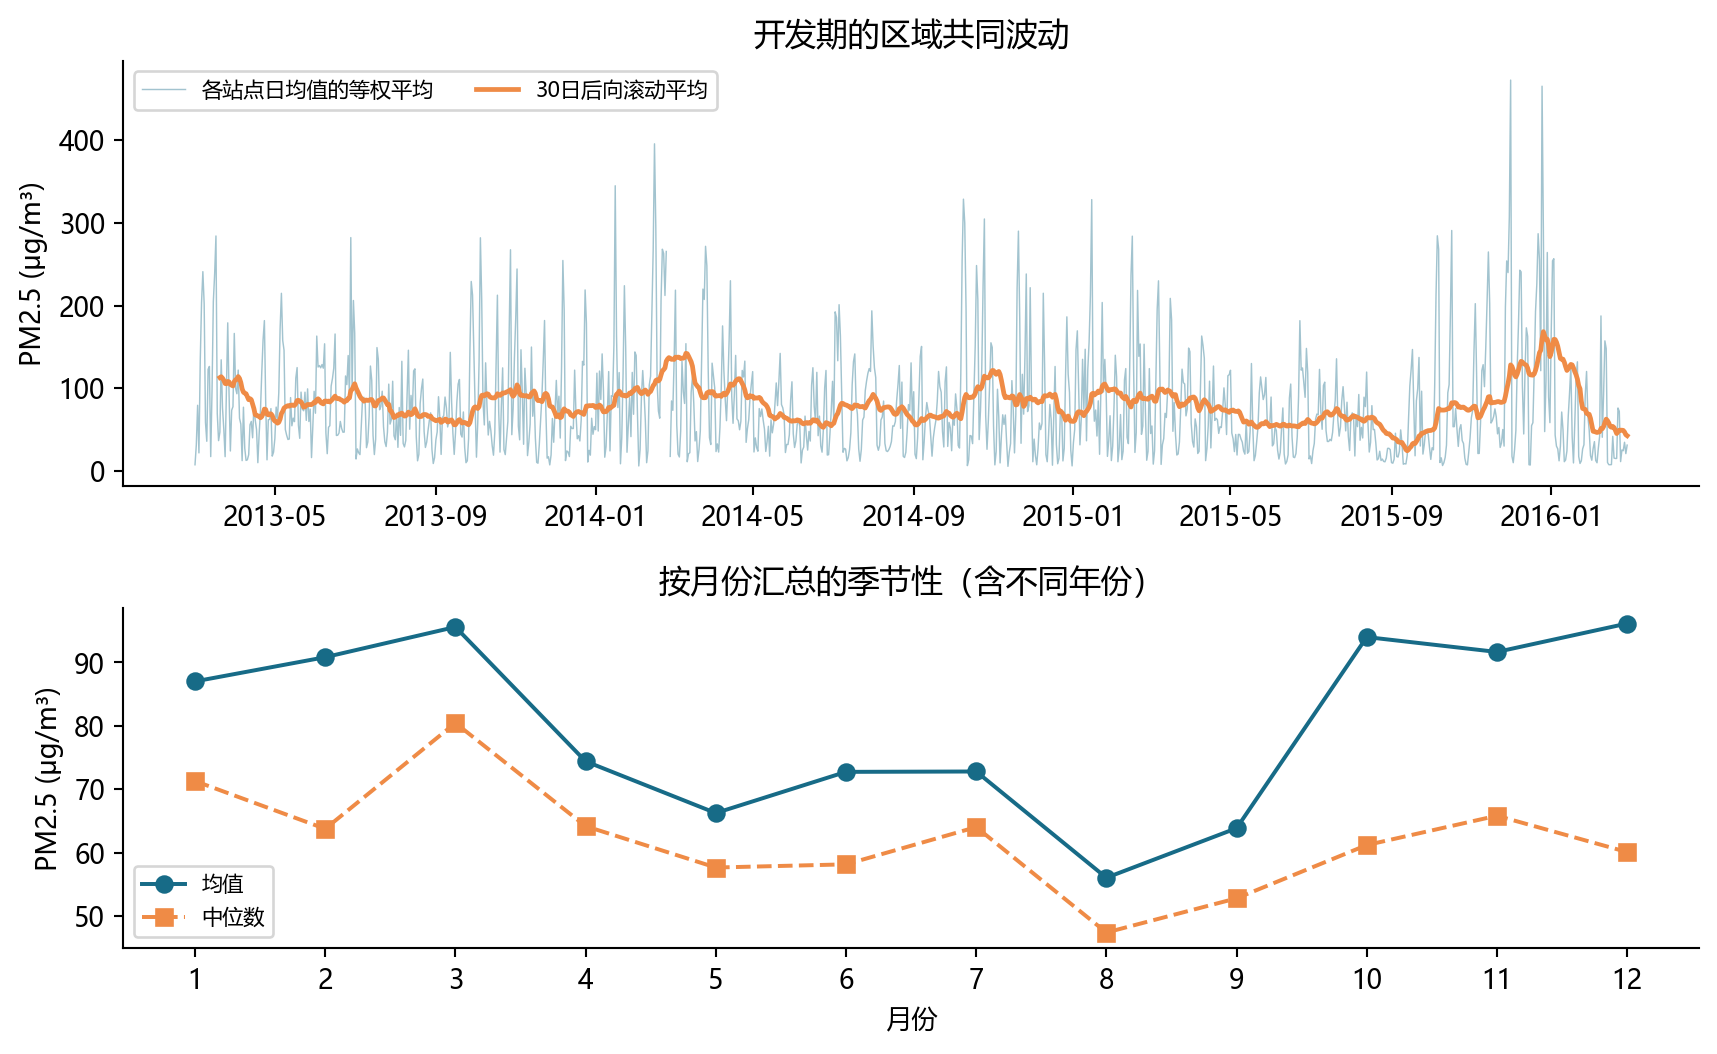

In [5]:
eda = read_json("eda_summary.json")
display(pd.Series({k:v for k,v in eda.items() if not isinstance(v,dict)},name="结果").to_frame())
show_fig("02_distribution.png")
show_fig("03_time.png")

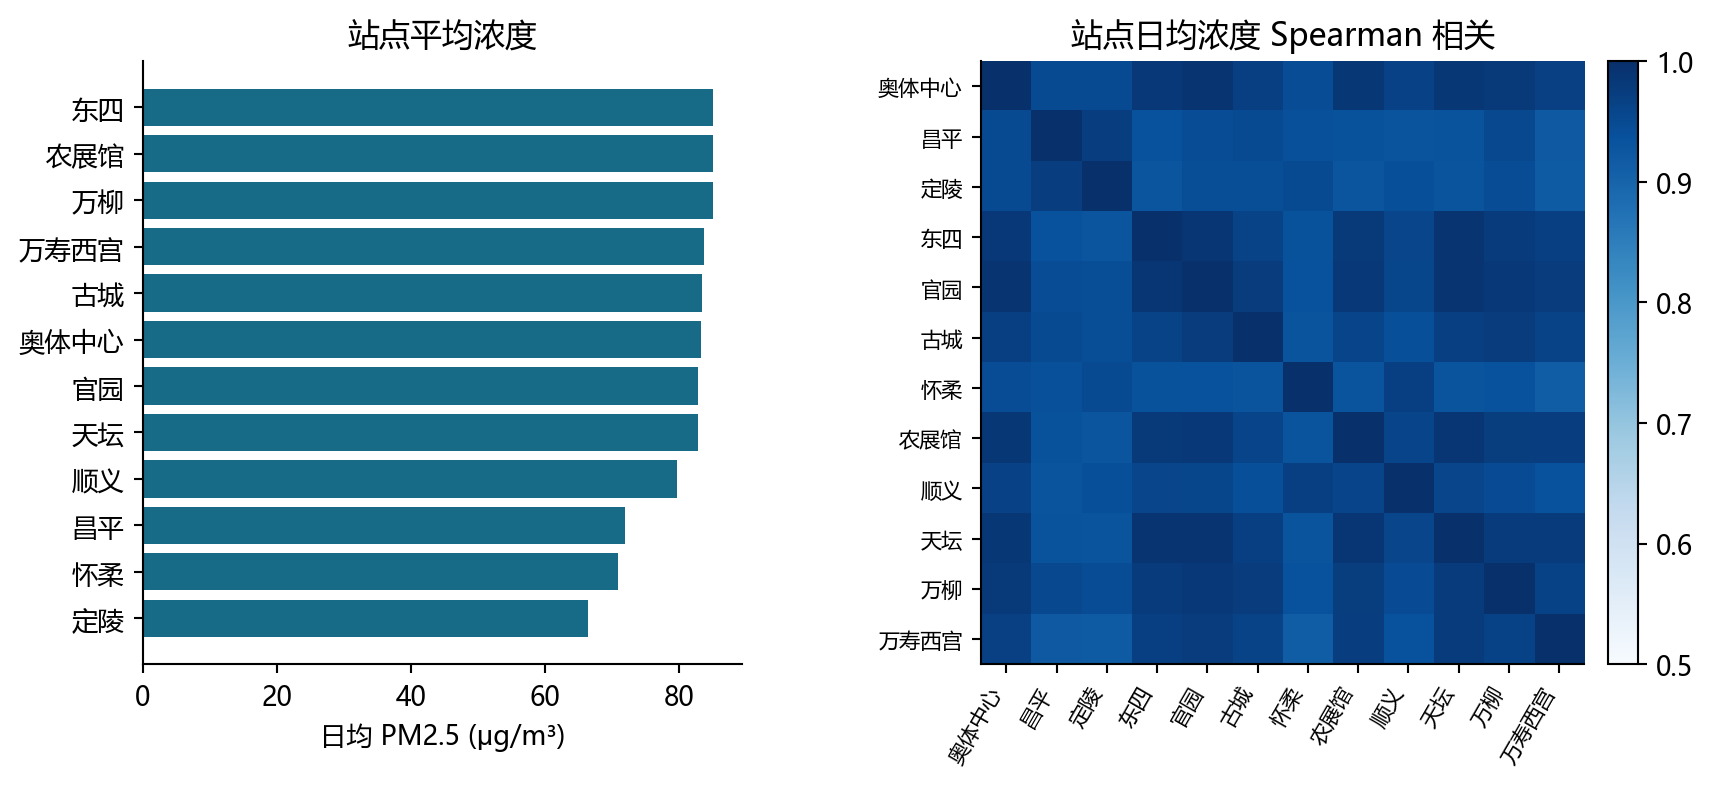

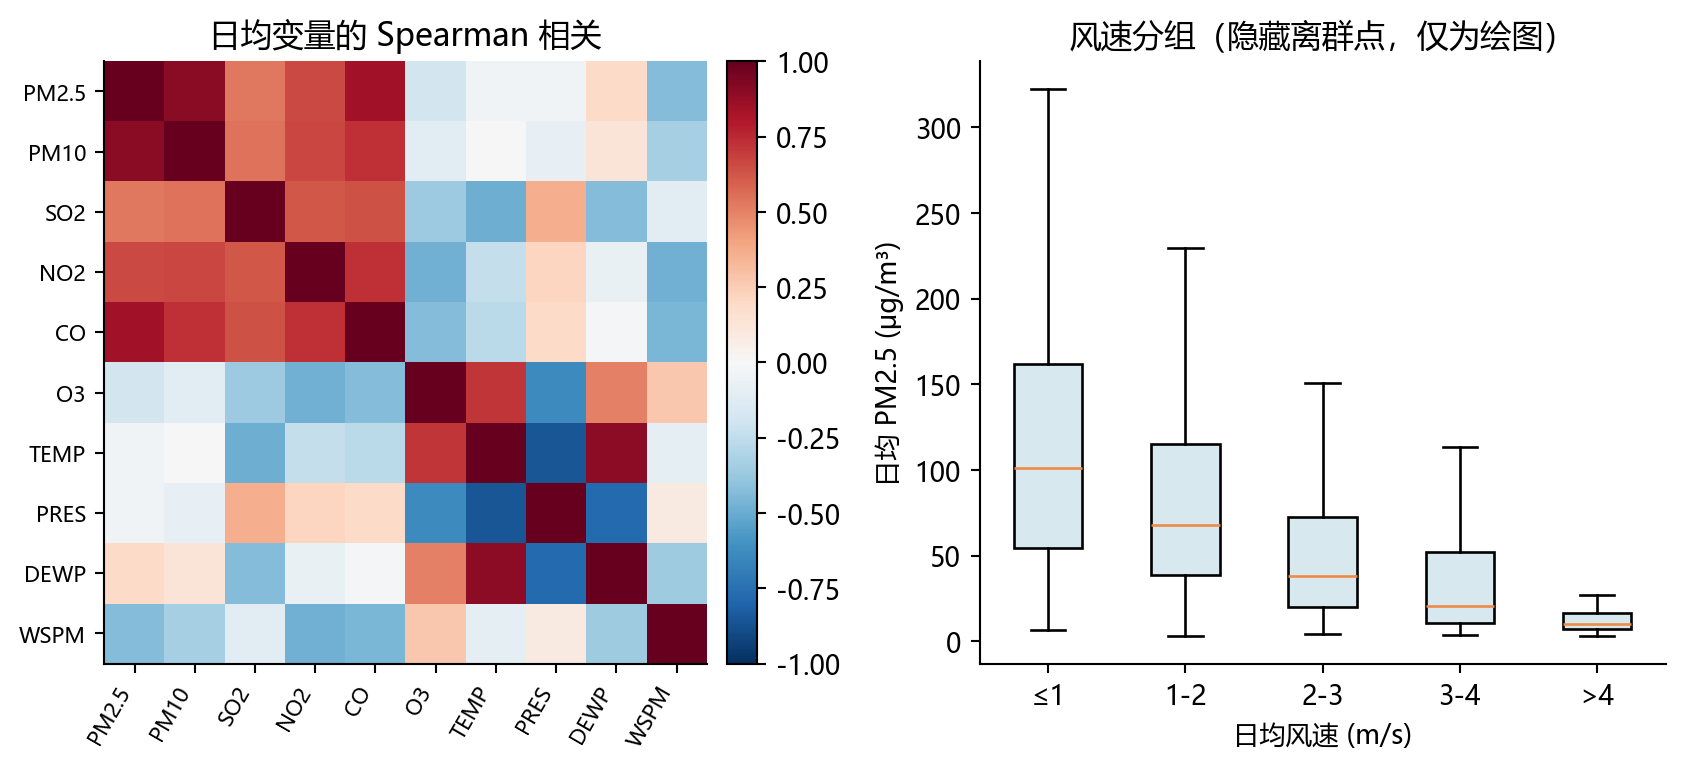

In [6]:
show_fig("04_stations.png")
show_fig("05_weather.png")

## 5. 严格的次日目标与时间验证

所有特征日期≤t，目标日期=t+1。先补齐日网格再shift，防止跳过缺失日期。按目标日期统一划分全部站点，训练目标早于验证特征日期。测试区间为完整日历年，但缺失筛选后不必每天都有可评估样本。

In [7]:
dev = frame[frame.target_date < TEST_START - pd.Timedelta(days=1)].reset_index(drop=True)
test = frame[frame.target_date >= TEST_START].reset_index(drop=True)
folds, descriptions = calendar_folds(dev)
display(pd.DataFrame(descriptions))
assert dev.target_date.max() < test.date.min()
assert not set(groups["full"]) & {"target","target_date","target_hours"}
missing_dates = pd.date_range("2016-03-01","2017-02-28").difference(test.target_date.unique())
print("测试可评估日期:", test.target_date.nunique(), "日")
print("无可评估站点的日期:", missing_dates.strftime("%Y-%m-%d").tolist())
print("站点日覆盖率:", f"{len(test)/(365*12):.2%}")

,train_start,train_end,valid_start,valid_end,n_train,n_valid
0,2013-03-02,2015-02-27,2015-03-01,2015-06-30,8442,1421
1,2013-03-02,2015-06-29,2015-07-01,2015-10-31,9863,1438
2,2013-03-02,2015-10-30,2015-11-01,2016-02-28,11301,1423


测试可评估日期: 363 日
无可评估站点的日期: ['2016-09-07', '2016-09-08']
站点日覆盖率: 96.21%


## 6. 三类算法与调参

岭回归用L2正则约束系数；随机森林通过多棵树平均学习非线性；HGB逐步拟合残差。均值与持续性提供参照。所有预处理在Pipeline内拟合；HGB关闭随机内部早停。共16组候选、每组3个时间折，以平均RMSE选择，不用测试集选模型。

仅依据开发期CV选择的模型: Ridge


,params,cv_rmse,cv_mae,cv_std,candidates,seconds
Ridge,{'estimator__model__alpha': 10},45.712351,32.696247,16.274935,4,1.011889
RandomForest,"{'estimator__model__max_depth': 10, 'estimator...",46.291542,31.852354,18.145281,4,95.302449
HistGradientBoosting,"{'estimator__model__l2_regularization': 10, 'e...",48.975971,34.048953,20.062759,8,34.105002


,model,params,mean_test_rmse,mean_train_rmse,rank_test_rmse
0,Ridge,{'estimator__model__alpha': 0.1},-45.718163,-44.169748,3
1,Ridge,{'estimator__model__alpha': 1},-45.716853,-44.169940,2
2,Ridge,{'estimator__model__alpha': 10},-45.712351,-44.173291,1
3,Ridge,{'estimator__model__alpha': 100},-45.764567,-44.212938,4
4,RandomForest,"{'estimator__model__max_depth': 10, 'estimator...",-46.699070,-23.570163,4
5,RandomForest,"{'estimator__model__max_depth': 10, 'estimator...",-46.291542,-26.206020,1
6,RandomForest,"{'estimator__model__max_depth': None, 'estimat...",-46.630632,-11.271118,3
7,RandomForest,"{'estimator__model__max_depth': None, 'estimat...",-46.424026,-20.187766,2
8,HistGradientBoosting,"{'estimator__model__l2_regularization': 0, 'es...",-50.733079,-23.291136,5
9,HistGradientBoosting,"{'estimator__model__l2_regularization': 0, 'es...",-49.403037,-15.863586,2


CSV采用sklearn负RMSE评分，表中取负即可获得通常的正RMSE。


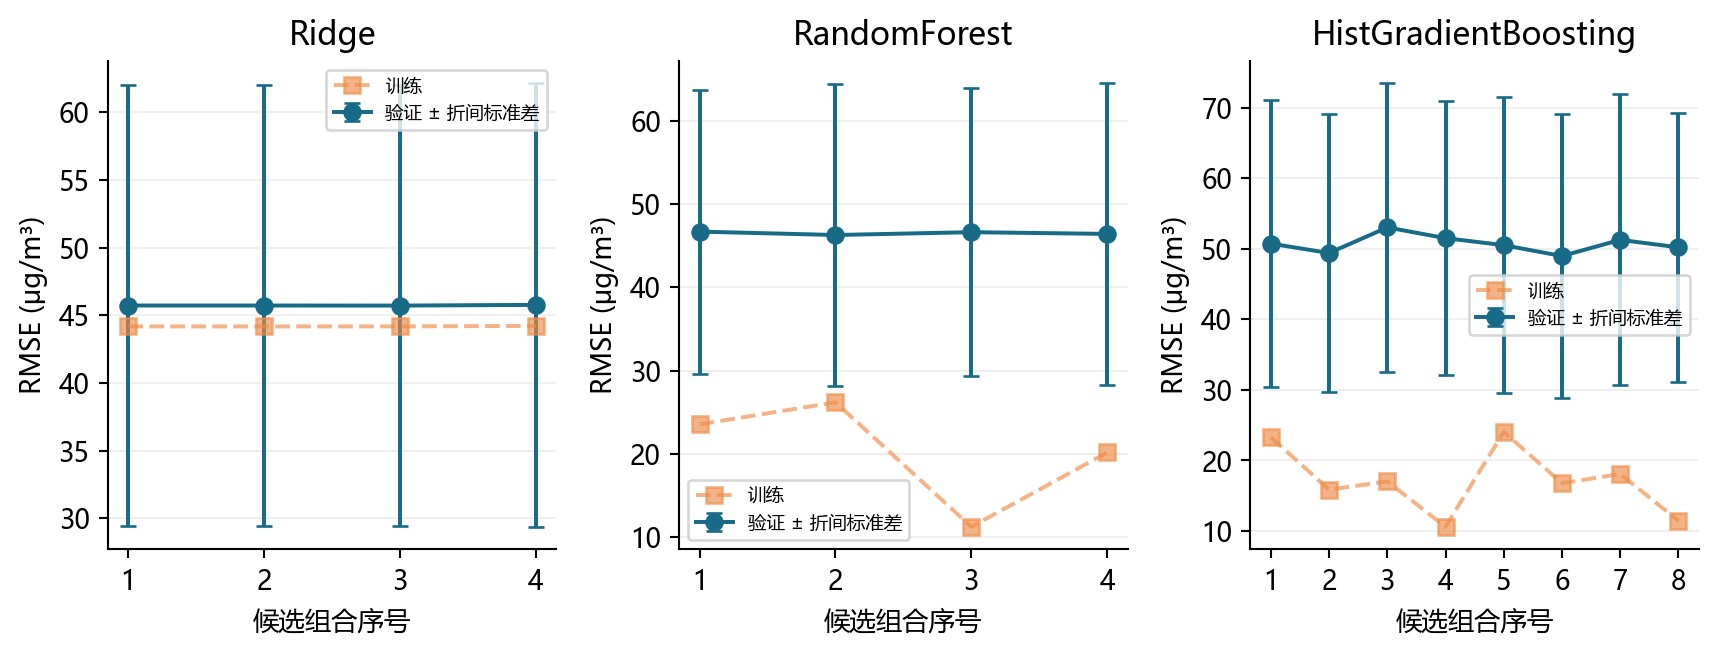

In [8]:
selection = read_json("model_selection.json")
print("仅依据开发期CV选择的模型:", selection["selected"])
display(pd.DataFrame(selection["tuning"]).T[["params","cv_rmse","cv_mae","cv_std","candidates","seconds"]])
cv = pd.read_csv(OUT / "cv_all.csv")
display(cv[["model","params","mean_test_rmse","mean_train_rmse","rank_test_rmse"]])
print("CSV采用sklearn负RMSE评分，表中取负即可获得通常的正RMSE。")
show_fig("06_tuning.png")

## 7. 独立测试结果

RMSE用于主比较，MAE描述典型误差，R²衡量相对目标均值常数的平方误差改善，Bias识别高估或低估。主模型由开发期CV选择，独立测试年用于评价泛化。

,CV_RMSE,MAE,RMSE,R2,Bias,predict_seconds
model,,,,,,
Ridge,45.7124,31.8671,46.1790,0.5910,-2.2487,0.0136
RandomForest,46.2915,33.2628,51.7214,0.4869,-1.6561,0.1283
HistGradientBoosting,48.9760,34.9769,54.2748,0.4350,-17.9945,0.0837
Persistence,61.0604,44.4794,66.2704,0.1577,0.1679,0.0006
TrainingMean,68.8470,51.8238,72.2296,-0.0006,1.8372,0.0019


相对持续性的RMSE下降: 30.32%


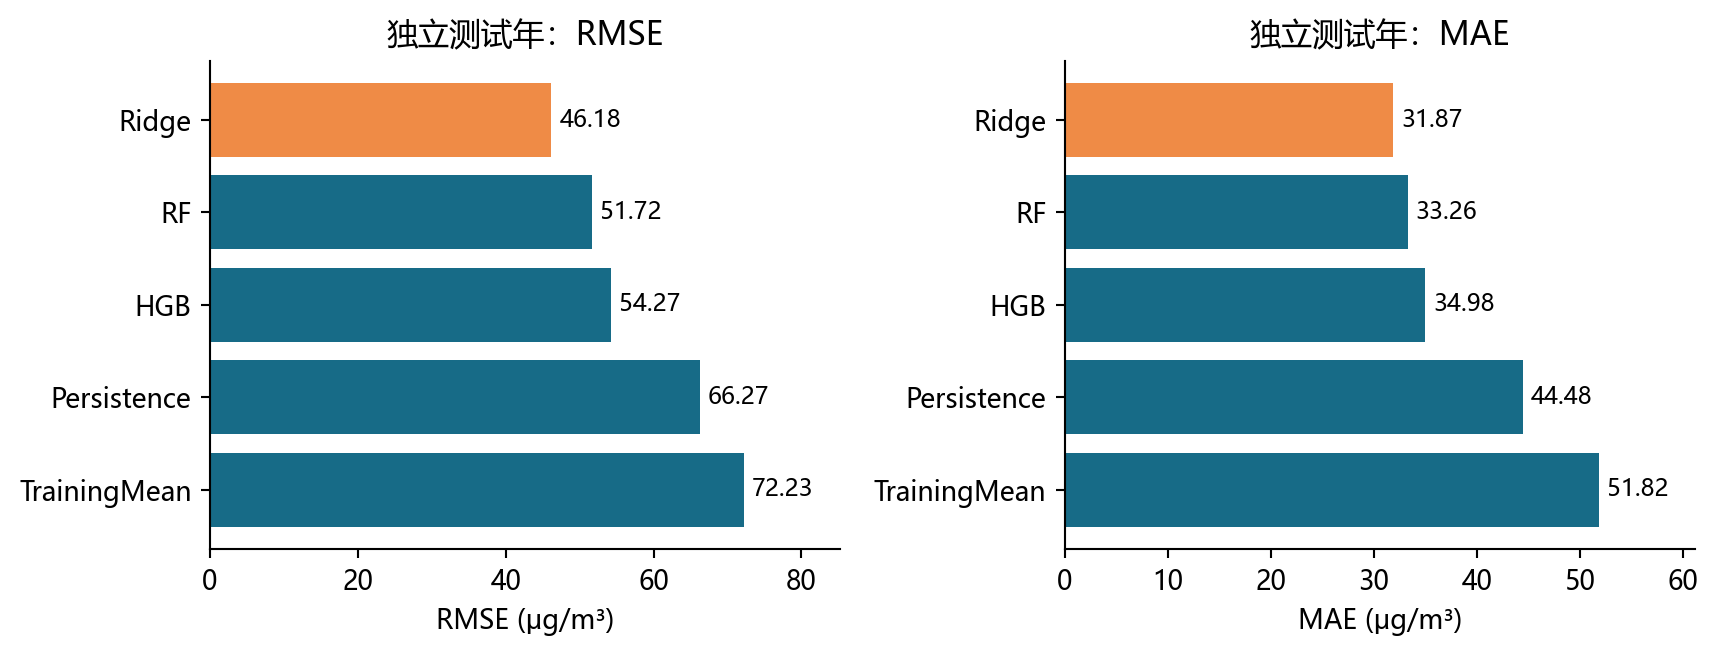

In [9]:
scores = pd.read_csv(OUT / "metrics.csv").set_index("model")
display(scores.round(4))
chosen = selection["selected"]
improvement = 1 - scores.loc[chosen,"RMSE"] / scores.loc["Persistence","RMSE"]
print(f"相对持续性的RMSE下降: {improvement:.2%}")
show_fig("07_models.png")

## 8. 残差、峰值和分组误差

主要指标在站点日层面计算。区域平均曲线仅辅助观察，可能掩盖站点误差。高浓度阈值来自开发目标90%分位数，不是国家空气质量标准。

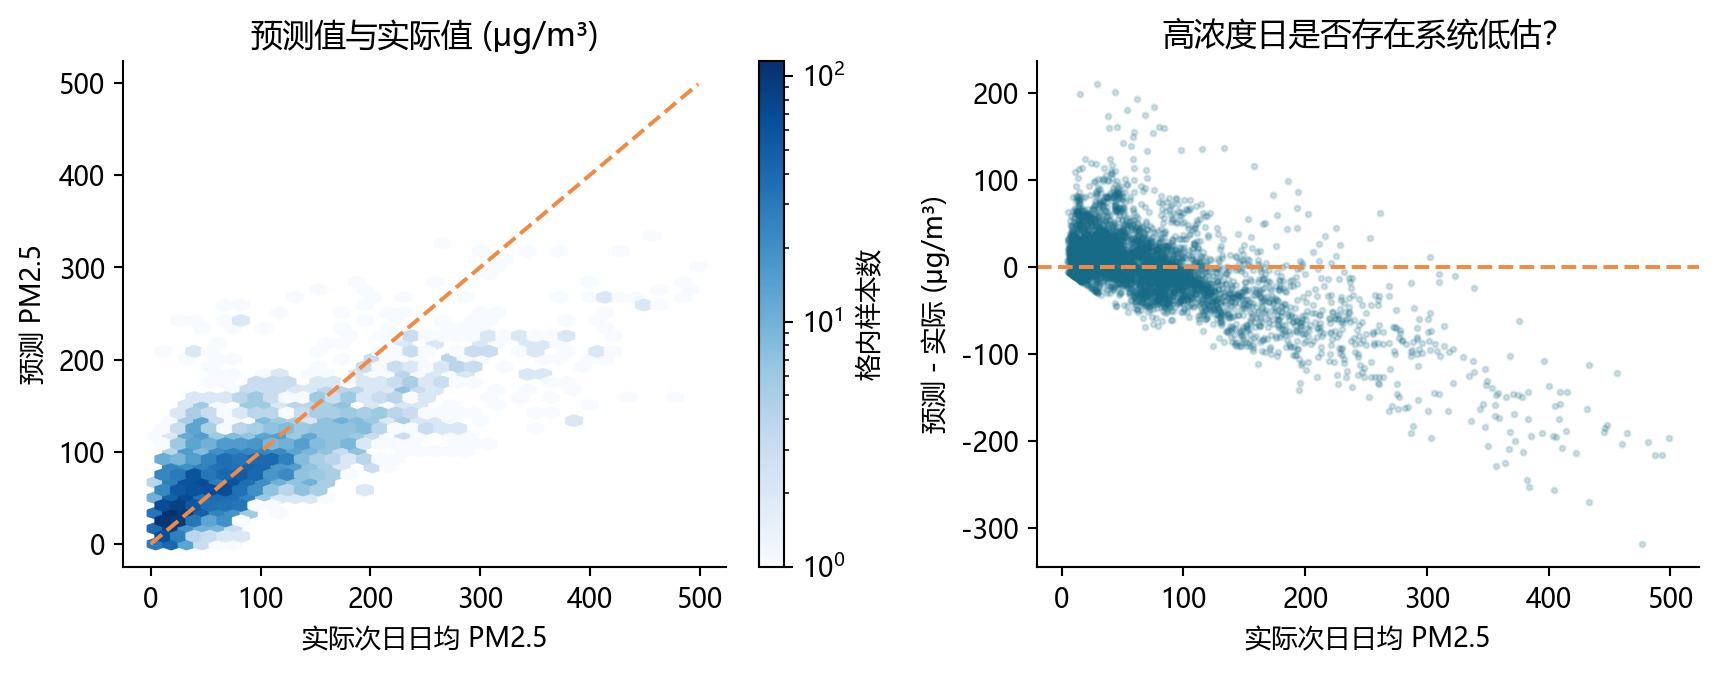

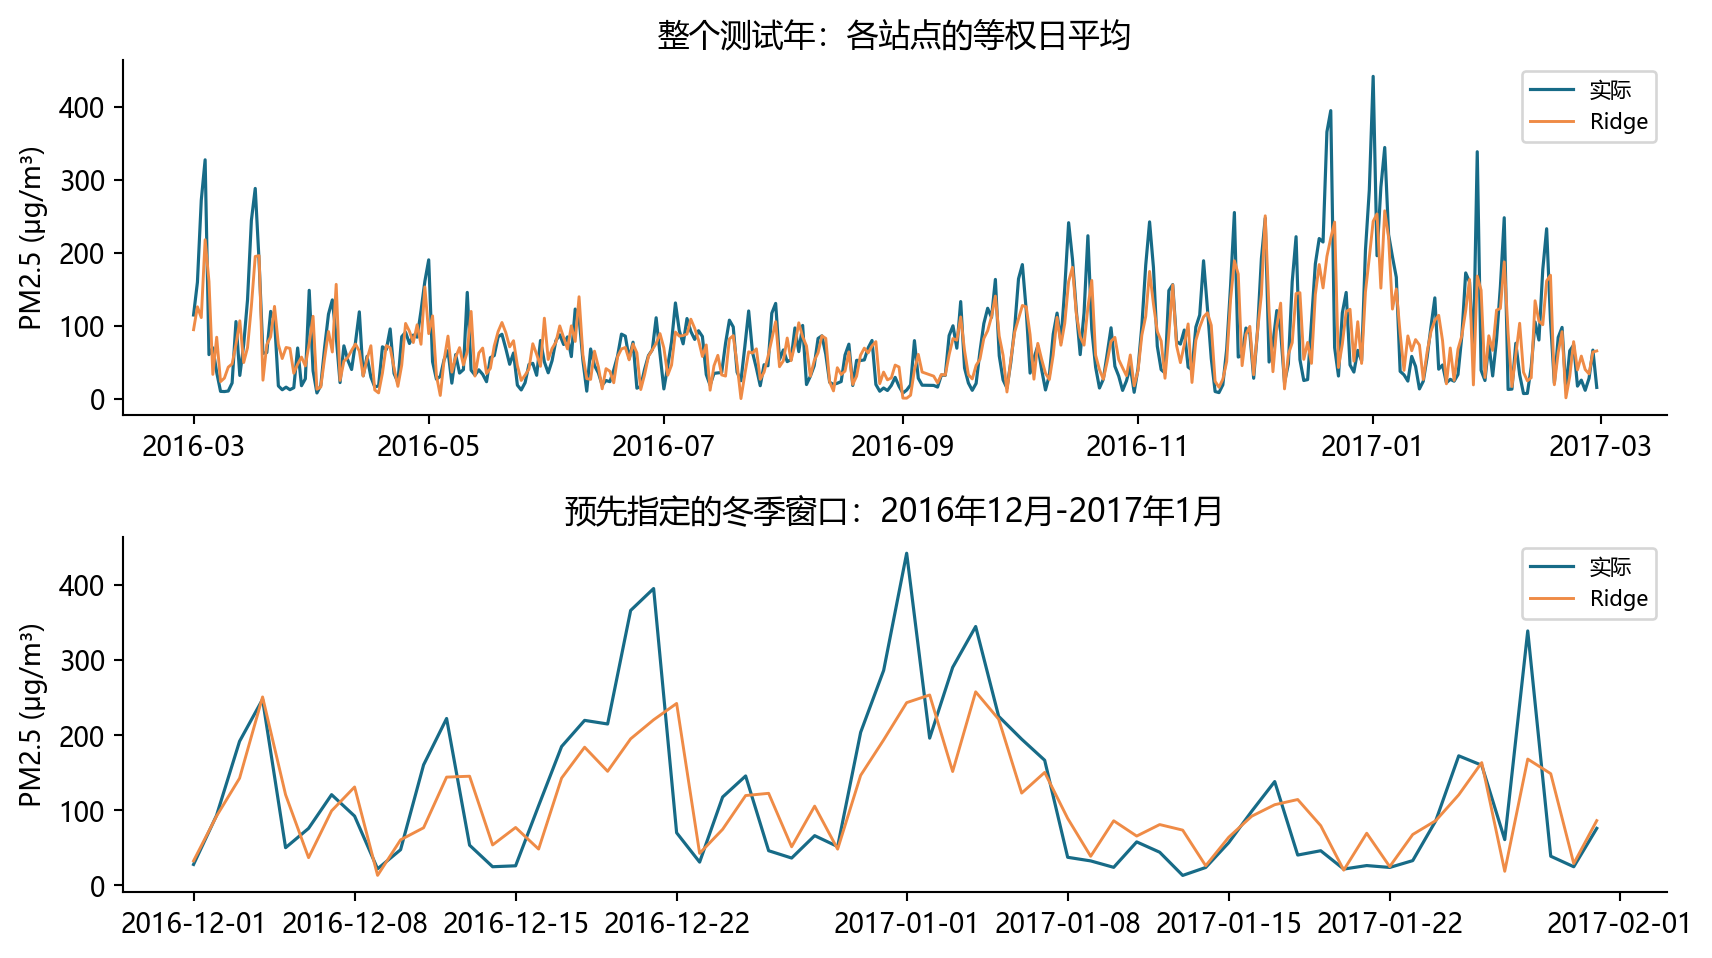

In [10]:
show_fig("08_residuals.png")
show_fig("09_predictions.png")

,dimension,group,n,MAE,RMSE,R2,Bias,persistence_RMSE
0,season,Autumn,1029,26.894,36.668,0.658,-4.857,57.481
1,season,Spring,1070,33.869,46.246,0.472,-0.447,58.803
2,season,Summer,1067,19.949,25.597,0.413,0.950,33.730
3,season,Winter,1048,46.840,66.362,0.584,-4.784,98.623
4,station,Aotizhongxin,352,32.426,46.435,0.599,0.805,68.751
5,station,Changping,361,28.419,44.016,0.514,-2.135,59.191
6,station,Dingling,351,28.241,41.265,0.526,-2.018,58.880
7,station,Dongsi,333,34.177,49.446,0.616,-4.369,72.689
8,station,Guanyuan,352,32.632,46.398,0.595,-1.065,67.519
9,station,Gucheng,355,33.913,50.387,0.577,-10.369,72.291


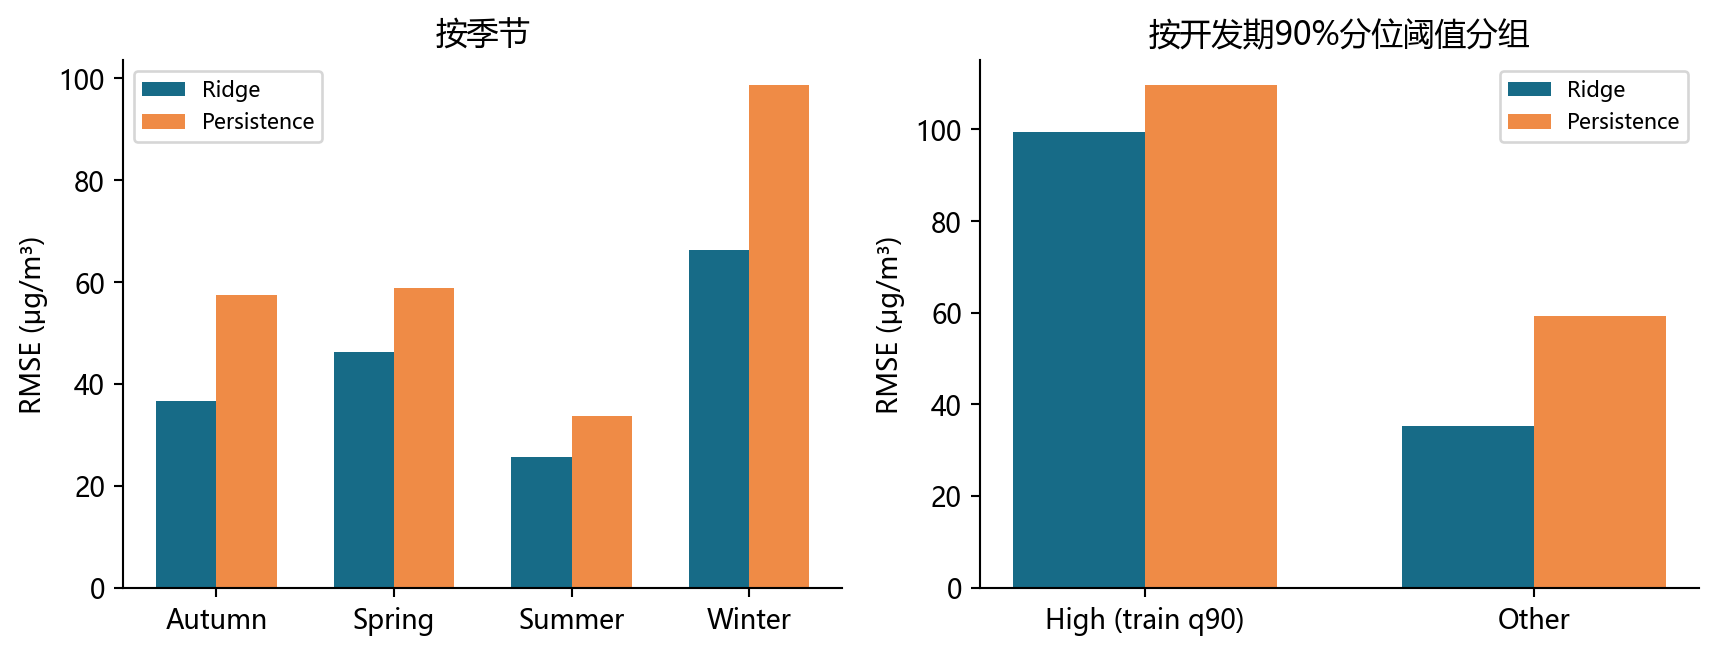

{'description': 'same fitted models; both days have >=20 valid PM hours',
 'n': 4170,
 'selected': {'MAE': 31.86504923387713,
  'RMSE': 46.20638989186313,
  'R2': 0.5919443682075683,
  'Bias': -2.2242018580577874},
 'persistence': {'MAE': 44.64314867135089,
  'RMSE': 66.47472679016289,
  'R2': 0.1554440585817487,
  'Bias': 0.24470384956856644}}

In [11]:
subgroups = pd.read_csv(OUT / "subgroups.csv")
display(subgroups.round(3))
show_fig("10_subgroups.png")
display(read_json("sensitivity.json"))

## 9. 配对块自助法与不确定性

连续7日为块，所有站点随日期共同抽取，共1500次。正差值表示所选模型优于参照。区间是给定模型、给定测试期的条件评估，不是未来任何年份的性能保证。

In [12]:
display(pd.DataFrame(read_json("bootstrap.json")))

,model,reference,block_days,repeats,rmse_improvement,ci95
0,Ridge,Persistence,7,1500,20.091476,"[14.353579244474071, 26.45424911044565]"
1,Ridge,RandomForest,7,1500,5.542438,"[1.634553471056271, 9.900225803361069]"


## 10. 置换重要性与消融

单变量置换可能打破合理的特征组合，相关变量也会相互替代，因此不能解释为因果效应。消融保持算法和参数不变；额外变量并不必然提升预测。主结果不根据解释实验改选。

,features,n_features,cv_rmse,fold1,fold2,fold3
0,history_calendar,16,46.5435,37.9186,34.8668,66.8450
1,with_weather,24,45.6296,35.6575,33.9487,67.2826
2,full,30,45.7124,34.9875,33.4384,68.7112


,feature,delta_rmse,std
0,pm_evening,49.7256,0.8685
1,pm_max,11.9930,0.9086
2,PM2.5,8.0658,1.8322
3,WSPM,2.3910,0.1900
4,city_pm,2.2006,0.4256
5,NO2,2.1115,0.2803
6,pm_lag1,1.4780,0.1556
7,pm_change,0.5890,0.1662
8,PRES,0.5093,0.1476
9,wind_cos,0.4416,0.2474


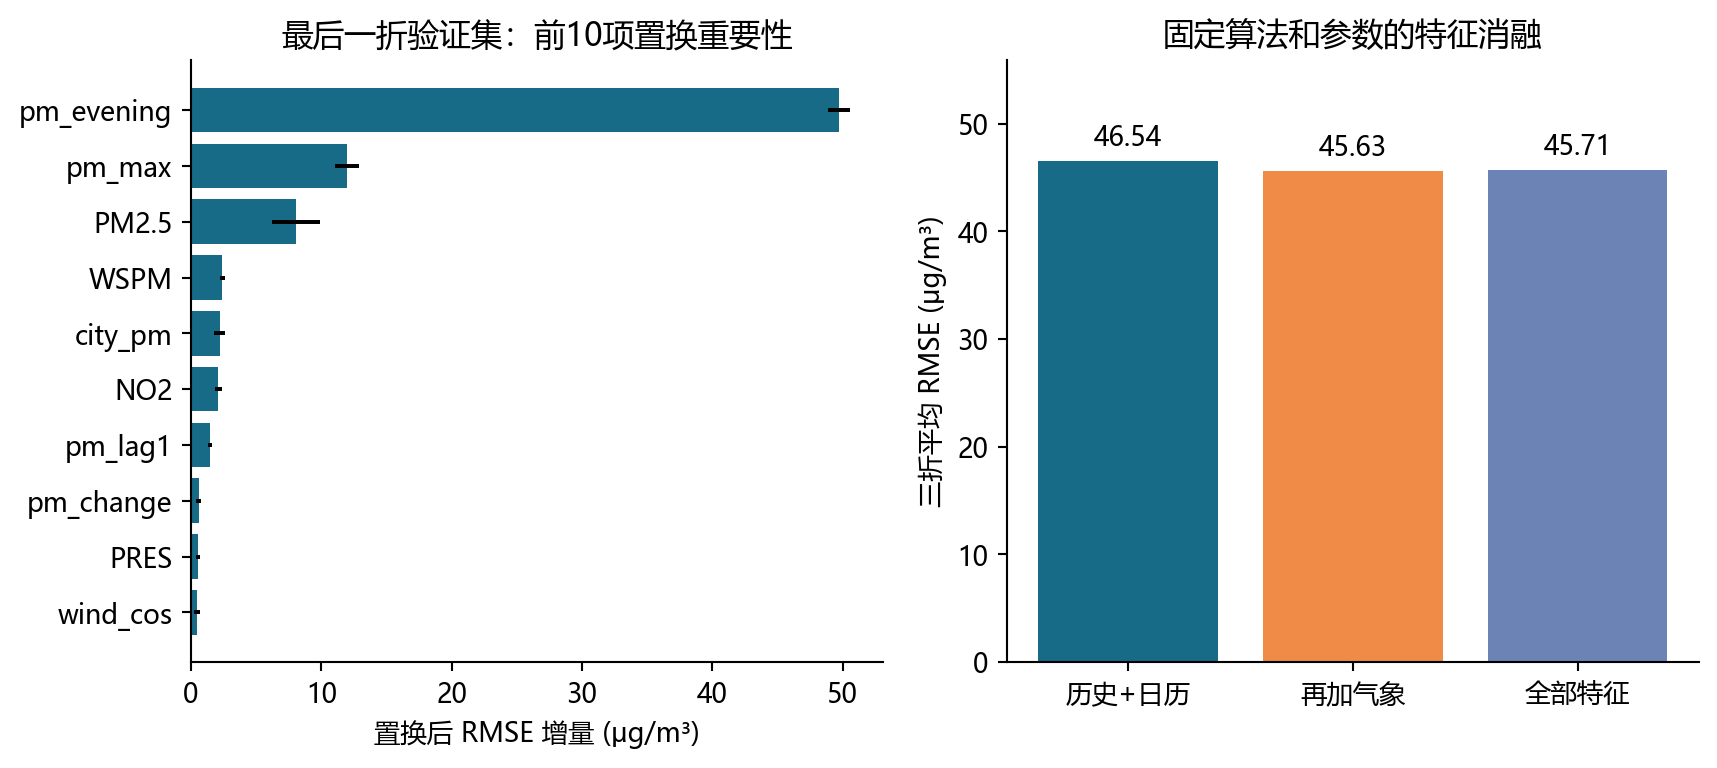

In [13]:
display(pd.read_csv(OUT / "ablation.csv").round(4))
display(pd.read_csv(OUT / "permutation_importance.csv").head(15).round(4))
show_fig("11_interpretation.png")

## 11. 补充稳健性与输入可获得性

执行 `python extended_analysis.py` 可重算补充实验。其算法与α保持固定，评价覆盖门槛、时间块长和关键输入的影响。补充实验在初次测试后开展，用于解释与稳健性诊断。

,features,n_features,CV_RMSE,fold1,fold2,fold3
0,full,30,45.7124,34.9875,33.4384,68.7112
1,no_evening,29,51.7462,36.6984,38.7045,79.8357
2,no_city,29,45.7830,34.9689,33.4753,68.9048
3,no_evening_or_city,28,51.8794,36.6663,38.7995,80.1725


,min_hours,n_train,n_test,coverage_pct,MAE,RMSE,R2,Bias,persistence_RMSE
0,18,12736,4214,96.2100,31.8671,46.1790,0.5910,-2.2487,66.2704
1,20,12580,4170,95.2055,31.9019,46.2342,0.5915,-1.4575,66.4747
2,24,10256,3187,72.7626,33.0053,47.9756,0.5820,-0.2502,69.3004


,min_hours,n_common,MAE,RMSE,R2,Bias
0,18,3187,32.5841,47.7052,0.5867,-1.7597
1,20,3187,32.6047,47.6900,0.5870,-0.9625
2,24,3187,33.0053,47.9756,0.5820,-0.2502


,model,reference,block_days,repeats,rmse_improvement,ci95
0,Ridge,Persistence,1,1500,20.091476,"[12.608858611134579, 26.514485478099157]"
1,Ridge,RandomForest,1,1500,5.542438,"[1.3360067530451087, 9.939381424435272]"
2,Ridge,Persistence,3,1500,20.091476,"[13.318996267788869, 26.574091061130527]"
3,Ridge,RandomForest,3,1500,5.542438,"[1.5982179717640936, 9.654335673480887]"
4,Ridge,Persistence,7,1500,20.091476,"[14.353579244474075, 26.45424911044565]"
5,Ridge,RandomForest,7,1500,5.542438,"[1.634553471056271, 9.900225803361062]"
6,Ridge,Persistence,14,1500,20.091476,"[13.692498499574118, 27.184039720352022]"
7,Ridge,RandomForest,14,1500,5.542438,"[1.6091713614685088, 9.957256999125587]"
8,Ridge,Persistence,28,1500,20.091476,"[12.852098649322398, 27.494574775287052]"
9,Ridge,RandomForest,28,1500,5.542438,"[2.0349998083443555, 9.552266528435243]"


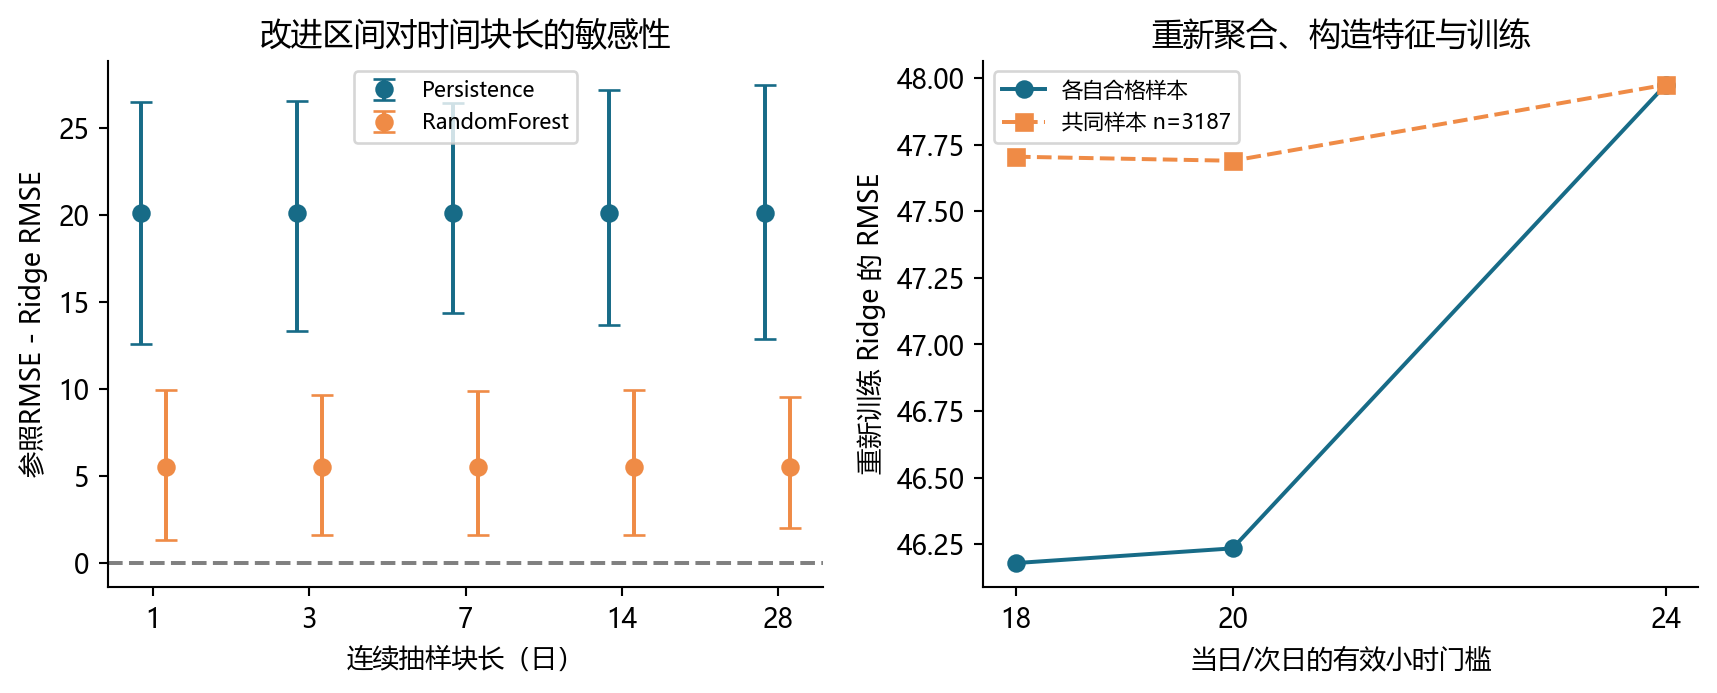

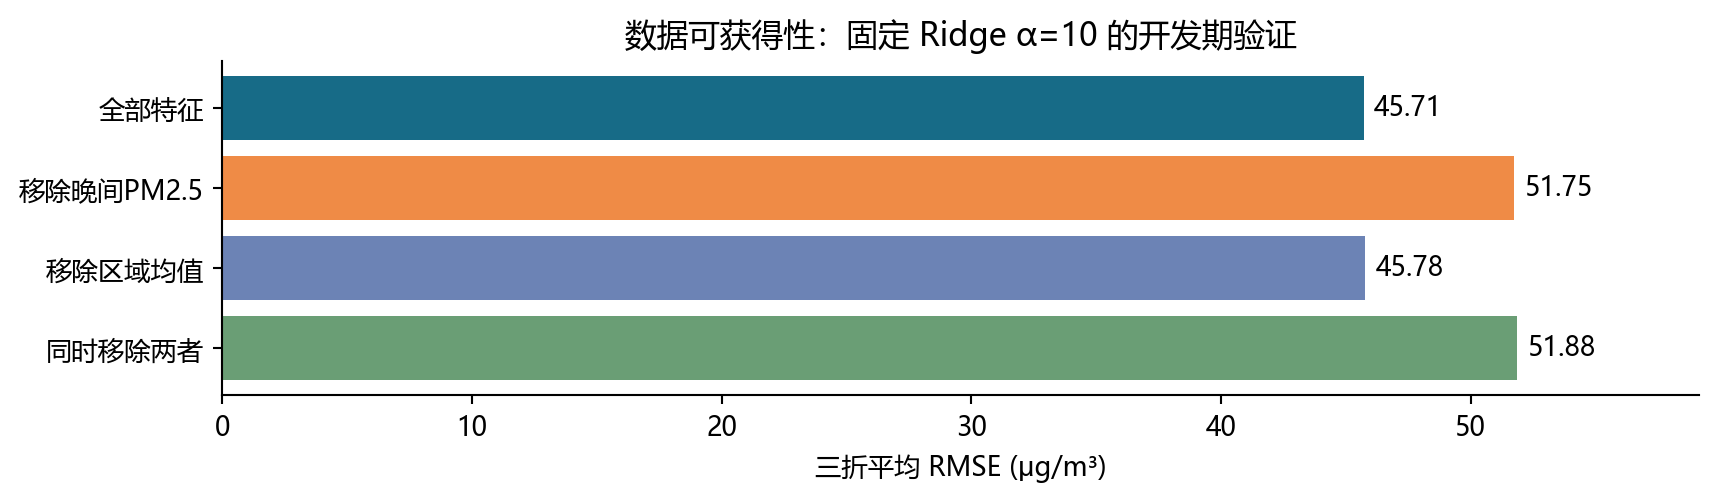

In [14]:
if RETRAIN or not (OUT / "extended_summary.json").exists():
    subprocess.run([sys.executable, "extended_analysis.py"], cwd=ROOT, check=True)
display(pd.read_csv(OUT / "feature_availability.csv").round(4))
display(pd.read_csv(OUT / "coverage_retraining.csv").round(4))
display(pd.read_csv(OUT / "coverage_common_sample.csv").round(4))
display(pd.DataFrame(read_json("block_sensitivity.json")))
show_fig("12_robustness.png")
show_fig("15_availability.png")

## 12. 高浓度事件、逐月误差与变化场景

高浓度阈值固定为开发目标90%分位数。岭回归提高精确率、降低误报，同时付出召回率下降的代价。按真实次日变动分组显示，稳定日持续性更好，快速升降时岭回归降低误差。变化组用于事后诊断。

,model,threshold,tn,fp,fn,tp,precision,recall,f1,n_alerts
0,Persistence,166.6667,3575,206,204,229,0.5264,0.5289,0.5276,435
1,Ridge,166.6667,3727,54,238,195,0.7831,0.4503,0.5718,249
2,RandomForest,166.6667,3684,97,229,204,0.6777,0.4711,0.5559,301
3,HistGradientBoosting,166.6667,3709,72,274,159,0.6883,0.3672,0.4789,231


{'threshold': 166.66666666666666,
 'high_n': 433,
 'high_fraction': 0.10275272899857618,
 'high_sse_fraction': 0.4776409810880243,
 'method': 'Supplementary diagnostics added after the initial test evaluation; main model/parameters unchanged.',
 'alpha': 10,
 'bootstrap_seed': 42,
 'bootstrap_repeats': 1500}

,month,n,target_mean,MAE,RMSE,R2,Bias,persistence_RMSE
0,2016-03,367,92.8081,49.1220,61.9062,0.5295,-7.5845,79.5385
1,2016-04,338,67.1865,24.4418,33.3558,0.3330,-3.5439,44.7660
2,2016-05,365,53.4195,27.2614,37.2276,-0.0350,9.5977,43.8145
3,2016-06,346,58.5445,19.0339,24.5549,0.3915,2.4136,32.9109
4,2016-07,351,68.0081,22.8027,28.6351,0.3810,-6.8627,38.2486
5,2016-08,370,45.6497,18.0985,23.4034,0.3064,6.9925,29.6678
6,2016-09,316,54.6380,17.4074,21.7741,0.7571,-0.3689,41.1189
7,2016-10,353,84.8126,30.0965,39.3123,0.6335,-4.7497,56.2632
8,2016-11,360,97.4678,32.0811,43.7227,0.5734,-8.9012,69.6854
9,2016-12,370,129.0320,56.0162,75.6399,0.4880,-14.0954,104.4563


,group,n,MAE,RMSE,R2,Bias,persistence_RMSE
0,Change <50,2892,21.5529,29.4423,0.6822,2.8796,25.1478
1,Decrease >=50,621,47.2204,60.4615,-0.5340,37.8635,129.3206
2,Increase >=50,701,60.8172,77.4900,0.2657,-58.9399,94.7442


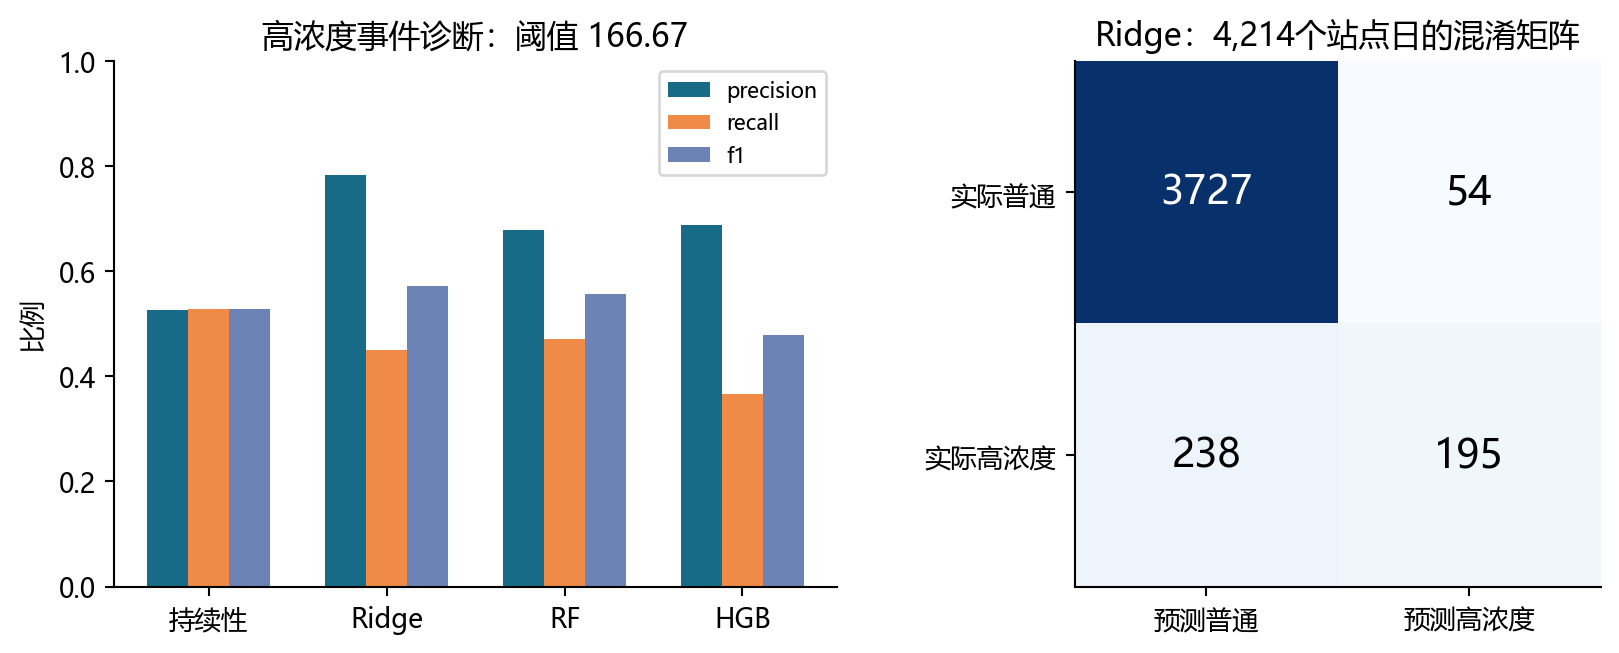

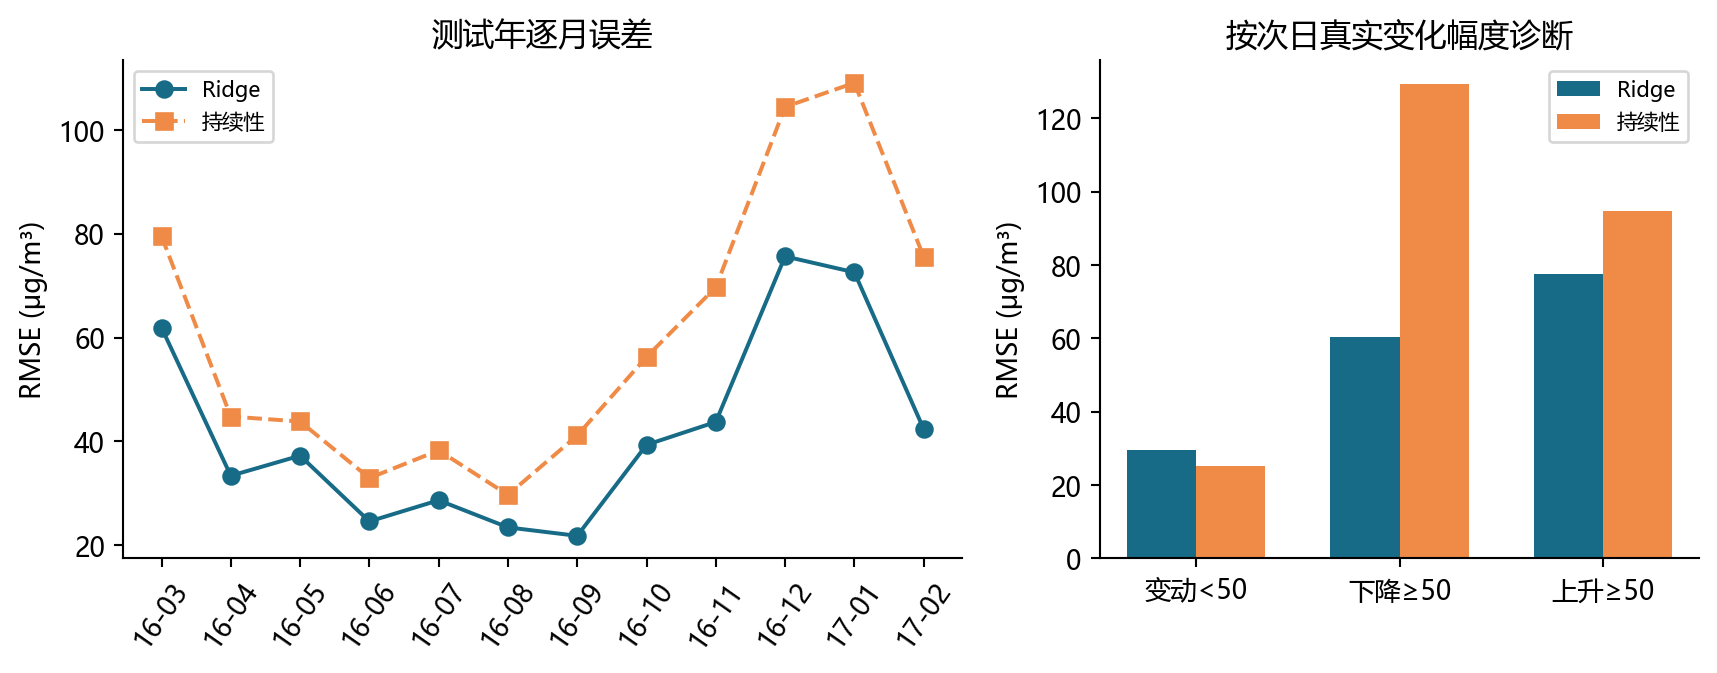

In [15]:
display(pd.read_csv(OUT / "high_event_diagnostics.csv").round(4))
display(read_json("extended_summary.json"))
display(pd.read_csv(OUT / "monthly_errors.csv").round(4))
display(pd.read_csv(OUT / "change_errors.csv").round(4))
show_fig("13_events.png")
show_fig("14_error_structure.png")

## 13. 可复现代码与检查

主实验：`python run_analysis.py`；补充实验：`python extended_analysis.py`；完整性检查：`python -m unittest discover -s tests -v`；报告重建：`python build_report.py`。测试覆盖时间对齐、未来扰动、评价样本、逐行指标、事件计数及共同样本评分。

In [16]:
display(read_json("environment.json"))
config = json.loads((ROOT / "project_config.json").read_text(encoding="utf-8"))
print("GitHub:", config["github_url"] or "未配置仓库地址")

{'python': '3.10.21',
 'platform': 'Windows-10-10.0.26200-SP0',
 'packages': {'numpy': '2.2.6',
  'pandas': '2.3.3',
  'matplotlib': '3.10.9',
  'scipy': '1.15.3',
  'scikit-learn': '1.7.2',
  'reportlab': '4.4.5',
  'pypdf': '6.2.0',
  'joblib': '1.6.0',
  'threadpoolctl': '3.8.0'},
 'seed': 42,
 'elapsed_seconds': 136.1657662000507}

GitHub: https://github.com/Screwllum/beijing-air-quality-python-final-2026


## 14. 结论与下一步

1. 覆盖门槛、训练内预处理与严格次日对齐构成可复现数据流程。
2. 晚间污染状态提供关键预测信息，移除后平均CV RMSE上升约6.03。
3. 岭回归总体RMSE比持续性低30.3%；平稳日持续性更好，快速升降时岭回归降低误差。
4. 岭回归高事件精确率78.3%、召回率45.0%，提示部署需联合权衡误报与漏报。
5. 后续可加入有真实发布时点的天气预报，开展滚动验证和分位数预测。数据与计算结果可追溯。